# Petz Recovery through a Single Polar Transformation for Approximate Quantum Error Correction

This is the working notebook for the following manuscript:

> Hanzhang Zhao and Shenglong Xu. *Petz Recovery through a Single Polar Transformation for Approximate Quantum Error Correction*. arXiv preprint [arXiv:2610.20515](https://arxiv.org/abs/2610.20515) (2026).

## Petz recovery

Let $\mathcal{E}$ describe encoding and noise from the logical system $A$ to the accessible output $D$:

$$
\mathcal{E}(\rho)=\sum_i E_i\rho E_i^\dagger,
\qquad \sum_i E_i^\dagger E_i=I_A.
$$

For a full-rank reference state $\sigma$ on $A$, the Petz recovery map is

$$
\mathcal{R}^{\mathrm{Petz}}_\sigma(\omega)
=\sigma^{1/2}\mathcal{E}^\dagger\!\left[
\mathcal{E}(\sigma)^{-1/2}\,\omega\,\mathcal{E}(\sigma)^{-1/2}
\right]\sigma^{1/2},
\qquad
\mathcal{E}^\dagger(X)=\sum_i E_i^\dagger X E_i.
$$

The inverse square root is taken on the support of $\mathcal{E}(\sigma)$ and is zero on its kernel. This map preserves trace on that support, which contains every encoded state when $\sigma$ is full rank.

Following the paper, introduce a Kraus-index register $C$ and construct the weighted row operator

$$
\boxed{
\tilde{E}_\sigma
=\sum_i \langle i|_C\otimes E_i\sqrt{\sigma}
=\begin{pmatrix}
E_0\sqrt{\sigma} & E_1\sqrt{\sigma} & \cdots & E_{d_C-1}\sqrt{\sigma}
\end{pmatrix}.
}
$$

It maps $\mathcal{H}_C\otimes\mathcal{H}_A$ to $\mathcal{H}_D$ and has matrix dimensions $d_D\times(d_Cd_A)$. For the unitary dilation $U:A\otimes B\to C\otimes D$, with $B$ initialized in $|0\rangle_B$, its blocks are obtained from

$$
E_i=(\langle i|_C\otimes I_D)U(I_A\otimes|0\rangle_B).
$$

The construction gives

$$
\tilde{E}_\sigma\tilde{E}_\sigma^\dagger
=\sum_i E_i\sigma E_i^\dagger
=\mathcal{E}(\sigma).
$$

In the code, `petz.generate_random_encoding` returns this weighted row operator, with columns ordered as $C\otimes A$. Recovery uses its adjoint.

Consequently, stacking the Petz Kraus operators gives the polar factor

$$
\begin{aligned}
R^{\mathrm{Petz}}_{\sigma,i}
&=\sqrt{\sigma}\,E_i^\dagger\mathcal{E}(\sigma)^{-1/2},\\
R^{\mathrm{Petz}}_\sigma
&=\sum_i |i\rangle_C\otimes R^{\mathrm{Petz}}_{\sigma,i}\\
&=\tilde{E}_\sigma^\dagger
\left(\tilde{E}_\sigma\tilde{E}_\sigma^\dagger\right)^{-1/2}
=\operatorname{sign}\!\left(\tilde{E}_\sigma^\dagger\right).
\end{aligned}
$$

Here $\operatorname{sign}$ acts on singular values, replacing each positive singular value by one and leaving zero unchanged. Tracing out $C$ recovers the Petz map:

$$
\mathcal{R}^{\mathrm{Petz}}_\sigma(\omega)
=\operatorname{tr}_C\!\left[
R^{\mathrm{Petz}}_\sigma\,\omega\,(R^{\mathrm{Petz}}_\sigma)^\dagger
\right].
$$


## Block encoding and QSVT

To implement the polar transformation, we first block encode $\tilde{E}_\sigma^\dagger$ in a unitary $W$:

$$
\boxed{\tilde{E}_\sigma^\dagger=\alpha\langle t|_T W|s\rangle_S,}
\qquad
\mathcal{H}_{\mathrm{ext}}
\cong\mathcal{H}_S\otimes\mathcal{H}_D
\cong\mathcal{H}_T\otimes\mathcal{H}_C\otimes\mathcal{H}_A.
$$

Here $|s\rangle_S$ and $|t\rangle_T$ are normalized auxiliary states, and $\alpha>0$ is the block-encoding normalization. Identities on the remaining registers are implicit in the matrix element. Write the singular value decomposition on the nonzero support as

$$
\tilde{E}_\sigma^\dagger
=\sum_i\lambda_i|E_i^{CA}\rangle\langle E_i^D|,
\qquad
x_i=\lambda_i/\alpha\in(0,1],
\qquad
\sum_i\lambda_i^2=1.
$$

Thus the encoded block has singular values $x_i$, while the Petz polar factor replaces each nonzero singular value by one.

### QSVT sequence

Define the auxiliary-state phase rotations

$$
\begin{aligned}
Z_s(\theta)
&=W\left[e^{i\theta|s\rangle\langle s|}\otimes I_D\right]W^\dagger,\\
Z_t(\theta)
&=e^{i\theta|t\rangle\langle t|}\otimes I_{CA}.
\end{aligned}
$$

After the initial application of $W$, alternate these rotations for $k$ iterations:

$$
W^{\vec\theta}
=Z_s(\theta_{2k})Z_t(\theta_{2k-1})\cdots
Z_s(\theta_2)Z_t(\theta_1)W,
\qquad
\vec\theta=(\theta_1,\ldots,\theta_{2k}).
$$

The resulting block is a singular-value polynomial transformation,

$$
\langle t|W^{\vec\theta}|s\rangle
=P=\sum_i p(x_i)|E_i^{CA}\rangle\langle E_i^D|.
$$

The full recovery isometry also contains a component orthogonal to $|t\rangle$:

$$
W^{\vec\theta}|s\rangle
=|t\rangle P+(I_T-|t\rangle\langle t|)W|s\rangle Q,
$$

where

$$
Q=\sum_i q(x_i)|E_i^D\rangle\langle E_i^D|
+q(0)\left(I_D-\sum_i|E_i^D\rangle\langle E_i^D|\right).
$$

The polynomials $p$ and $q$ are odd and even, respectively, with degrees at most $2k+1$ and $2k$. Unitarity gives

$$
|p(x)|^2+(1-x^2)|q(x)|^2=1.
$$

At $k=0$, $p(x)=x$ and $q(x)=1$. Setting all angles to $\pi$ gives the Grover sequence. To approximate Petz recovery, choose the angles so that $p(x_i)\approx1$ up to a **common phase** across all nonzero singular values; large $|p(x_i)|$ alone does not ensure this phase alignment.

### Recovery without postselection

Prepare $|s\rangle$, apply $W^{\vec\theta}$, and discard $T$ and $C$:

$$
\mathcal{R}^{\vec\theta}(\omega)
=\operatorname{tr}_{TC}\!\left[
W^{\vec\theta}(|s\rangle\langle s|\otimes\omega)
(W^{\vec\theta})^\dagger
\right].
$$

This is a trace-preserving channel. As $p$ approaches the singular-value sign function, its action on encoded inputs approaches $\mathcal{R}^{\mathrm{Petz}}_\sigma\circ\mathcal{E}$, with the orthogonal component suppressed.

The unconditional recovery also depends on the full block-encoding isometry $W|s\rangle$. For the generic type-I and type-II constructions and the reduced type-II′ Hayden–Preskill construction used below, tracing out the auxiliary registers of this unprojected isometry leaves $\sigma$ independently of the input. The fidelity routine uses this property to calculate the failure contribution.

In the code below, `qsvt.qsvt_pq(x, angles)` evaluates $(p(x),q(x))$ for the given scaled singular values and angle sequence.


## Optimal polynomials for the sign function

Suppose all nonzero scaled singular values $x_i=\lambda_i/\alpha$ lie in $[a,b]$, with $0<a<b\leq1$. For $k$ QSVT iterations, we seek a real odd polynomial $r$ of degree at most $2k+1$ that approximates $\operatorname{sgn}(x)=1$ uniformly on this interval:

$$
\boxed{
\begin{aligned}
1-\delta^{[a,b]}(k)
&=\max_r\;\min_{x\in[a,b]}r(x),\\
\text{subject to}\qquad
&r\in\mathbb{R}[x],\qquad \deg r\leq2k+1,\\
&r(-x)=-r(x),\\
&|r(x)|\leq1\qquad\text{for every }x\in[-1,1].
\end{aligned}
}
$$

The bound must hold on the entire interval $[-1,1]$, even when the approximation is optimized only on $[a,b]$. Oddness gives the same approximation error on the negative interval $[-b,-a]$.

The real polynomial is realized by QSVT as

$$
r(x)=\operatorname{Re}\!\left[e^{-i\phi}p(x)\right],
$$

where $p$ is the complex QSVT polynomial and $\phi$ is a common phase. In the cells below, `qsvt.generate_interval_polynomial(k=2*k, a=a, b=b)` constructs the real target polynomial for $k$ iterations.


In [1]:
from pathlib import Path
import sys

# Shared QSVT module lives one directory above this notebook.
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import qsvt_sign as qsvt
import petz

Path("figure").mkdir(parents=True, exist_ok=True)


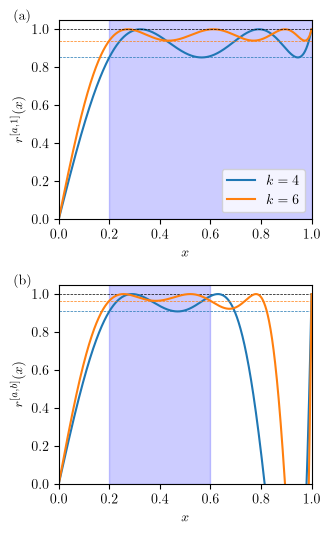

In [2]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
})

width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(2,1,
    figsize=(width_in, height_in*2),
    tight_layout=True
)
plt.sca(ax[0])

xs = np.linspace(0,1,1000)
p = qsvt.generate_polynomial(k=8, eps=0.2)
plt.plot(xs, p(xs), label=r'$k=4$')
plt.axhline(y=p(0.2), color='tab:blue', linestyle='--', linewidth=0.5)
xs = np.linspace(0,1,1000)
p = qsvt.generate_polynomial(k=12, eps=0.2)
plt.plot(xs, p(xs), label=r'$k=6$')
plt.axhline(y=p(0.2), color='tab:orange', linestyle='--', linewidth=0.5)
plt.xlabel('$x$')
plt.ylabel(r'$r^{[a,1]}(x)$')
plt.axhline(y=1, color='black', linestyle='--', linewidth=0.5)
plt.xlim(0,1)
plt.ylim(0,1.05)
plt.axvspan(xmin=0.2, xmax=1, color='blue', alpha=0.2)

plt.legend()
plt.text(-0.18, 1, '(a)', transform=plt.gca().transAxes)

plt.sca(ax[1])
plt.axhline(y=1, color='black', linestyle='--', linewidth=0.5)
p = qsvt.generate_interval_polynomial(k=8, a=0.2, b=0.6)
plt.plot(xs, p(xs), label=r'$k=4$')
plt.axhline(y=p(0.2), color='tab:blue', linestyle='--', linewidth=0.5)
p = qsvt.generate_interval_polynomial(k=12, a=0.2, b=0.6)
plt.plot(xs, p(xs), label=r'$k=6$')
plt.axhline(y=p(0.2), color='tab:orange', linestyle='--', linewidth=0.5)
plt.xlabel('$x$')
plt.ylabel(r'$r^{[a,b]}(x)$')
plt.xlim(0,1)
plt.ylim(0,1.05)
plt.axvspan(xmin=0.2, xmax=0.6, color='blue', alpha=0.2)
plt.text(-0.18, 1, '(b)', transform=plt.gca().transAxes)

fig.savefig('figure/optimal_poly_a.pdf', bbox_inches='tight')

### Asymptotic error for $b=1$

For $b=1$ and fixed $0<a<1$, the optimal approximation error has the asymptotic form

$$
\boxed{
\delta^{[a,1]}(k)\sim
\frac{2(1-a)}{\sqrt{\pi a k}}
\left(\frac{1-a}{1+a}\right)^k,
\qquad k\to\infty.
}
$$

The underlying best-uniform-approximation asymptotics are due to Alexandre Eremenko and Peter Yuditskii:

- [Uniform approximation of sgn(x) by polynomials and entire functions](https://arxiv.org/abs/math/0604324), *Journal d’Analyse Mathématique* **101**, 313–324 (2007).
- [Polynomials of the best uniform approximation to sgn(x) on two intervals](https://arxiv.org/abs/1008.3765), *Journal d’Analyse Mathématique* **114**, 285–315 (2011).

The following plot compares the numerically optimized error with this asymptotic expression.


/tmp/ipykernel_226832/3255410817.py:18: RuntimeWarning: divide by zero encountered in divide
  delta_asy = 2*(1-a)/np.sqrt(np.pi*a*K)*((1-a)/(1+a))**K
/tmp/ipykernel_226832/3255410817.py:30: RuntimeWarning: divide by zero encountered in divide
  delta_asy = 2*(1-a)/np.sqrt(np.pi*a*K)*((1-a)/(1+a))**K


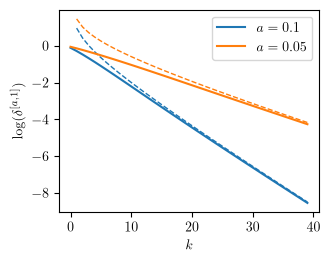

In [3]:
width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(1,1,
    figsize=(width_in, height_in),
    tight_layout=True
)

a=0.1
delta = []
K = range(40)
K = np.array(K)
for k in K:
    p = qsvt.generate_interval_polynomial(k=2*k, a=a, b=1)
    delta.append(1-p(a))
plt.plot(K, np.log(delta), color='tab:blue', label=f'$a={a}$')
delta_asy = 2*(1-a)/np.sqrt(np.pi*a*K)*((1-a)/(1+a))**K
plt.plot(K, np.log(delta_asy), '--', color='tab:blue', linewidth=1)


a = 0.05
delta = []
K = range(40)
K = np.array(K)
for k in K:
    p = qsvt.generate_interval_polynomial(k=2*k, a=a, b=1)
    delta.append(1-p(a))
plt.plot(K, np.log(delta), color='tab:orange', label=f'$a={a}$')
delta_asy = 2*(1-a)/np.sqrt(np.pi*a*K)*((1-a)/(1+a))**K
plt.plot(K, np.log(delta_asy), '--', color='tab:orange', linewidth=1)
plt.xlabel('$k$')
plt.ylabel(r'$\log(\delta^{[a,1]})$')
plt.legend()
fig.savefig('figure/delta_k.pdf', bbox_inches='tight')


    

### Spectrum-weighted loss and diamond-distance bound

For a QSVT polynomial $p^{\vec\theta}$, the spectrum-weighted loss is

$$
\mathcal{I}^{\vec\theta}
=1-\left|\sum_i\lambda_i^2p^{\vec\theta}(x_i)\right|^2,
\qquad
x_i=\lambda_i/\alpha,
\qquad
\sum_i\lambda_i^2=1.
$$

Let $r_k^{[a,b]}$ be the optimal interval max–min polynomial and $p_k^{[a,b]}$ a corresponding QSVT polynomial, with

$$
r_k^{[a,b]}(x)=\operatorname{Re}\!\left[e^{-i\phi}p_k^{[a,b]}(x)\right].
$$

If every nonzero $x_i$ lies in $[a,b]$, then

$$
\begin{aligned}
\left|\sum_i\lambda_i^2p_k^{[a,b]}(x_i)\right|
&\geq\operatorname{Re}\!\left[e^{-i\phi}\sum_i\lambda_i^2p_k^{[a,b]}(x_i)\right]\\
&=\sum_i\lambda_i^2r_k^{[a,b]}(x_i)\\
&\geq1-\delta^{[a,b]}(k).
\end{aligned}
$$

Therefore the interval max–min error bounds the weighted loss:

$$
\boxed{
\mathcal{I}_k^{[a,b]}
\leq1-\left(1-\delta^{[a,b]}(k)\right)^2
=2\delta^{[a,b]}(k)-\left[\delta^{[a,b]}(k)\right]^2
\leq2\delta^{[a,b]}(k).
}
$$

Direct spectrum-weighted optimization minimizes $\mathcal{I}^{\vec\theta}$ over all QSVT angle sequences at the same iteration count. Since the interval construction is one admissible choice,

$$
\min_{\vec\theta}\mathcal{I}^{\vec\theta}
\leq\mathcal{I}_k^{[a,b]}.
$$

Thus interval optimization controls the weighted loss using only an interval containing the spectrum, while direct weighted optimization uses the individual singular values. For $b=1$, the asymptotic expression above gives a corresponding exponentially decaying upper bound on the weighted loss.

For a full-rank reference state $\sigma$, the weighted loss bounds the diamond distance between the approximate and ideal Petz encoding–recovery channels:

$$
\boxed{
\Delta(\vec\theta)
=\frac{1}{2}\left\|
\mathcal{R}^{\vec\theta}\circ\mathcal{E}
-\mathcal{R}^{\mathrm{Petz}}_\sigma\circ\mathcal{E}
\right\|_\diamond
\leq\sqrt{\|\sigma^{-1}\|_\infty\,\mathcal{I}^{\vec\theta}}.
}
$$

The weighted loss therefore controls the worst-case channel error, including inputs entangled with a reference system; it is not itself the diamond distance. For the interval-optimized sequence $\vec\theta_k^{\,[a,b]}$, this gives

$$
\Delta\!\left(\vec\theta_k^{\,[a,b]}\right)
\leq\sqrt{\|\sigma^{-1}\|_\infty
\left\{1-\left[1-\delta^{[a,b]}(k)\right]^2\right\}}
\leq\sqrt{2\|\sigma^{-1}\|_\infty\,\delta^{[a,b]}(k)}.
$$

For $\sigma=I_A/d_A$, the factor $\|\sigma^{-1}\|_\infty$ is $d_A$.


## Numerical examples

We apply the recovery construction to two channels: unassisted Haar-random encoding and entanglement-assisted Hayden–Preskill encoding. Both examples use one logical qubit, $n_A=1$, and the maximally mixed recovery reference $\sigma$ and fidelity input $\tau$, with $\sigma=\tau=I_A/d_A$. In the code, `N`, `A`, and `D` count qubits: $n$, $n_A$, and $n_D$, with $d_X=2^{n_X}$.

Each example follows the same steps: compute the ideal Petz fidelity as a benchmark, examine the scaled singular values $x_i=\lambda_i/\alpha$, and compare approximate recovery for four angle sequences as the iteration count $k$ increases. The examples differ in the encoding channel, the registers available to the decoder, and the block-encoding normalization $\alpha$. Ideal-fidelity baselines use $n=8$ and $n=12$; the spectrum studies and angle-sequence comparisons use $n=8$.

### Entanglement fidelity

We evaluate recovery using

$$
F^{\mathrm{en}}\!\left(\mathcal{R}\circ\mathcal{E}\right)
=\langle\mathrm{EPR}|_{A'A}
\left[\operatorname{id}_{A'}\otimes
\left(\mathcal{R}\circ\mathcal{E}\right)\right]
\left(|\mathrm{EPR}\rangle_{A'A}\langle\mathrm{EPR}|\right)
|\mathrm{EPR}\rangle_{A'A},
$$

where $|\mathrm{EPR}\rangle_{A'A}=d_A^{-1/2}\sum_{j=0}^{d_A-1}|j\rangle_{A'}|j\rangle_A$ is normalized. The fidelity is $1/d_A^2=1/4$ when no information is accessible and is one for perfect recovery. We compare $\mathcal{R}=\mathcal{R}^{\vec\theta}$ with ideal Petz recovery $\mathcal{R}^{\mathrm{Petz}}_\sigma$.

### Four angle sequences

At each iteration count $k$, we use:

1. **Spectrum-weighted optimization**, $\vec\theta_k^{\mathrm{w}}$: optimize a bounded real odd polynomial using the full singular-value spectrum, then synthesize the corresponding QSVT angles to minimize $\mathcal{I}^{\vec\theta}=1-|\sum_i\lambda_i^2p^{\vec\theta}(x_i)|^2$.
2. **Tight-interval optimization**, $\vec\theta_k^{\,[x_{\min},x_{\max}]}$: synthesize the max–min polynomial on the interval containing all nonzero scaled singular values, using both spectral endpoints.
3. **Optimization on $[x_{\min},1]$**, $\vec\theta_k^{\,[x_{\min},1]}$: synthesize the max–min polynomial using the smallest nonzero scaled singular value and the block-encoding bound $x\leq1$.
4. **Grover search**: set every angle to $\theta_i=\pi$, independently of the spectrum.

Each sequence contains $2k$ angles and implements a polynomial of degree at most $2k+1$. The combined plots show unconditional recovery fidelities, without postselection, together with the ideal Petz benchmark.

### Shared fidelity calculation

`petz.Approx_Petz_entanglement_fidelity` returns unconditional and postselected fidelities. Passing `angle=None` gives the exact Petz benchmark; passing `angle=[]` gives zero QSVT iterations, with $p(x)=x$ and $q(x)=1$.

`calculate_fidelity_curve(U, D, K, angle_sequence, A=1, entanglement=False)` computes the fidelity curve for any of these choices. `K` contains iteration counts, and `angle_sequence(k)` returns the corresponding `2*k` angles. The helper returns unconditional and postselected fidelities; arrays ending in `_p` store the latter. Set `entanglement=False` for unassisted encoding and `entanglement=True` for Hayden–Preskill encoding.


In [4]:
def calculate_fidelity_curve(U, D, K, angle_sequence, A=1, entanglement=False):
    """Return deterministic and postselected fidelities for each iteration k in K.

    angle_sequence(k) supplies the 2*k QSVT angles for the chosen method.
    The recovery reference and fidelity input are maximally mixed.
    """
    fidelities = []
    postselected_fidelities = []
    for k in tqdm(K):
        angles = angle_sequence(k)
        fidelity, postselected_fidelity = petz.Approx_Petz_entanglement_fidelity(
            U, D=D, A=A, angle=angles, entanglement=entanglement
        )
        fidelities.append(fidelity)
        postselected_fidelities.append(postselected_fidelity)
    return np.array(fidelities), np.array(postselected_fidelities)


### Haar-random encoding

#### Encoding and ideal Petz fidelity

We encode a logical state $\rho_A$ by preparing the auxiliary register $B$ in $|0\rangle_B$ and applying a Haar-random unitary $U:A\otimes B\to C\otimes D$. The decoder has access to $D$, while $C$ is discarded. The encoding and noise channel is

$$
\mathcal{E}(\rho_A)
=\operatorname{tr}_C\!\left[
U\left(\rho_A\otimes|0\rangle_B\langle0|\right)U^\dagger
\right].
$$

The qubit counts satisfy $n=n_A+n_B=n_C+n_D$.

The following cells generate one Haar-random unitary with `seed=42` for each size $n=8$ and $n=12$, compute the ideal fidelity as $n_D$ varies, and plot it against $n_D-n/2$. Each curve uses a single unitary realization.


In [5]:
N=8
U8 = petz.generate_random_unitary(N, seed=42);

N=12
U12 = petz.generate_random_unitary(N, seed=42);


In [6]:
N=8
# angle=None gives exact Petz recovery; [0] selects unconditional fidelity.
f_petz8=[]
for D in tqdm(range(0, N+1)):
    f_petz8.append(petz.Approx_Petz_entanglement_fidelity(U8, D=D, A=1, angle=None)[0])
f_petz12=[]
N=12
for D in tqdm(range(0, N+1)):
    f_petz12.append(petz.Approx_Petz_entanglement_fidelity(U12, D=D, A=1, angle=None)[0])

100%|██████████| 13/13 [00:00<00:00, 378.50it/s]


/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


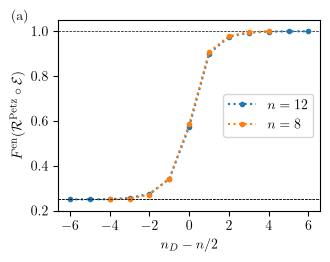

In [7]:

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
})

width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(
    figsize=(width_in, height_in),
    tight_layout=True
)

ax.axhline(
    y=0.25,
    color='black',
    linestyle='--',
    linewidth=0.5
)
ax.axhline(
    y=1,
    color='black',
    linestyle='--',
    linewidth=0.5
)

ax.plot(range(-6, 7), f_petz12, 'o:', label=r'$n=12$', markersize=3)
ax.plot(range(-4, 5), f_petz8, 'o:', label=r'$n=8$', markersize=3)


ax.set_ylim(0, 1.05)

ax.set_ylabel(r'$F^{\mathrm{en}}(\mathcal{R}^{\mathrm{Petz}}\circ \mathcal{E})$')
ax.set_xlabel(r'$n_D-n/2$')
plt.xticks(np.arange(-6,7,2))
ax.legend()
plt.ylim(0.2,1.05)
plt.text(-0.18, 1, '(a)', transform=plt.gca().transAxes)

ax.axhline(
    y=0.25,
    color='black',
    linestyle='--',
    linewidth=0.5
)

fig.savefig(
    'figure/petz_fidelity.pdf',
    bbox_inches='tight'
)

#### Scaled singular-value spectrum

We use the same $n=8$ unitary `U8`, with $n_A=1$, and vary $n_D$ from zero to eight. For the generic block encodings, choose

$$
\alpha^2=\min(d_A d_C,d_D),
\qquad x_i=\lambda_i/\alpha.
$$

The rank is $r=\min(d_A d_C,d_D)$ almost surely. Since $\sum_i\lambda_i^2=1$, the root-mean-square (RMS) scaled singular value is

$$
x_{\mathrm{rms}}=\sqrt{\overline{x^2}}
=\frac{1}{\sqrt{r\alpha^2}}
=\frac{1}{\min(d_A d_C,d_D)}.
$$

The left panel shows the spectral band $[x_{\min},x_{\max}]$ and the RMS value versus $n_D$. The right panel compares the first Grover-peak estimates

$$
k^*(x)=\frac{\pi}{4\arcsin x}-\frac12
$$

at $x=x_{\min}$ and $x=x_{\mathrm{rms}}$. These are continuous single-sector estimates; a broad spectrum need not reach its first peak at a common integer iteration count. The RMS curve is not the arithmetic mean of the singular values.


In [8]:
# Unassisted Haar encoding: n=8 and one logical qubit.
N, A = 8, 1
haar_n_D = np.arange(N + 1)
haar_x_min, haar_x_max, haar_x_rms = [], [], []

for D in tqdm(haar_n_D):
    C = N - D
    E_d = petz.generate_random_encoding(U8, D=D, A=A, entanglement=False)
    s = np.linalg.svd(E_d, compute_uv=False)
    alpha = np.sqrt(min(2**(A + C), 2**D))
    # Bound roundoff at x=1 before evaluating arcsin.
    x = np.minimum(s / alpha, 1.0)
    haar_x_min.append(np.min(x))
    haar_x_max.append(np.max(x))
    haar_x_rms.append(np.sqrt(np.mean(x**2)))

haar_x_min = np.array(haar_x_min)
haar_x_max = np.array(haar_x_max)
haar_x_rms = np.array(haar_x_rms)
haar_k_min = np.pi / (4*np.arcsin(haar_x_min)) - 0.5
haar_k_rms = np.pi / (4*np.arcsin(haar_x_rms)) - 0.5


100%|██████████| 9/9 [00:00<00:00, 1724.40it/s]


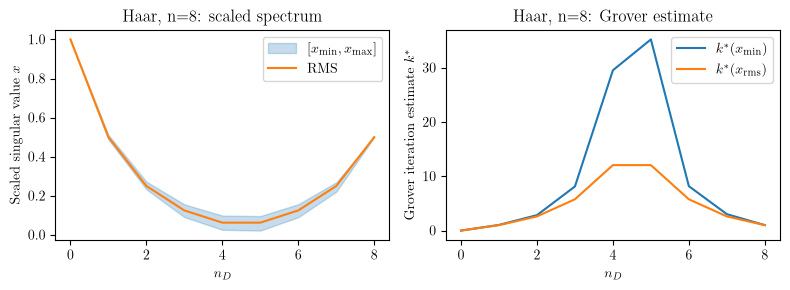

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), tight_layout=True)

axes[0].fill_between(
    haar_n_D, haar_x_min, haar_x_max,
    color='tab:blue', alpha=0.25, label=r'$[x_{\min},x_{\max}]$'
)
axes[0].plot(haar_n_D, haar_x_rms, color='tab:orange', label='RMS')
axes[0].set_xlabel(r'$n_D$')
axes[0].set_ylabel(r'Scaled singular value $x$')
axes[0].set_title('Haar, n=8: scaled spectrum')
axes[0].legend()

axes[1].plot(haar_n_D, haar_k_min, label=r'$k^*(x_{\min})$')
axes[1].plot(haar_n_D, haar_k_rms, label=r'$k^*(x_{\mathrm{rms}})$')
axes[1].set_xlabel(r'$n_D$')
axes[1].set_ylabel(r'Grover iteration estimate $k^*$')
axes[1].set_title('Haar, n=8: Grover estimate')
axes[1].legend()

fig.savefig('figure/spectrum_haar.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


#### Approximate Petz recovery

We compare the four angle sequences introduced above using $n=8$, $n_A=1$, and $n_D=6$, with the generic type-I block encoding $\alpha=\sqrt{d_A d_C}$. The setup cell calls `calculate_fidelity_curve` for each sequence with `entanglement=False`. The following combined plot shows the unconditional fidelities versus $k$ and the ideal Petz benchmark.


In [10]:
# Shared setup: one logical qubit, n=8, and n_D=6.
N, A, D = 8, 1, 6
C = N - D
K = np.arange(30)  # QSVT iterations; each sequence contains 2*k angles.

# Scaled singular values for the generic block encoding.
E_d = petz.generate_random_encoding(U8, D=D, A=A, entanglement=False)
s = np.linalg.svd(E_d, compute_uv=False)
alpha = np.sqrt(min(2**(A + C), 2**D))
x = s / alpha
a, b = np.min(x), np.max(x)
f_petz = f_petz8[D]  # Ideal Petz fidelity computed above.

# 1. Spectrum-weighted sequence: use the full scaled spectrum x.
f_weighted, f_weighted_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_weighted_angles(2*k, lambdas=x), A=A
)

# 2. Tight-interval sequence: optimize on [x_min, x_max] = [a, b].
f_intb, f_intb_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_interval_angles(2*k, a=a, b=b), A=A
)

# 3. Lower-bound sequence: optimize on [x_min, 1] = [a, 1].
f_int, f_int_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_interval_angles(2*k, a=a, b=1), A=A
)

# 4. Grover sequence: all 2*k angles equal pi.
f_grover, f_grover_p = calculate_fidelity_curve(
    U8, D, K, lambda k: np.pi*np.ones(2*k), A=A
)
# Arrays ending in _p contain postselected fidelities; the plot uses deterministic ones.


100%|██████████| 30/30 [00:00<00:00, 1024.53it/s]


/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


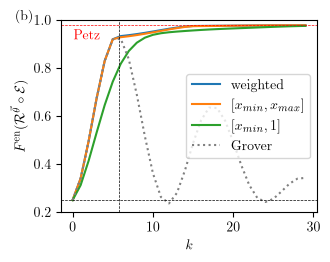

In [11]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
})

width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(
    figsize=(width_in, height_in),
    tight_layout=True
)


plt.plot(K, f_weighted, label='weighted')
plt.plot(K, f_intb, label='$[x_{min},x_{max}]$')
plt.plot(K, f_int, label='$[x_{min},1]$')
plt.plot(K, f_grover,'grey',linestyle=':',label='Grover')
plt.axhline(y=f_petz, color='r', linestyle='--', linewidth=0.5)
plt.axhline(y=0.25, color='black', linestyle='--', linewidth=0.5)
plt.xlabel('$k$')
plt.ylabel(r'$F^{\mathrm{en}}(\mathcal{R}^{\vec{\theta}}\circ\mathcal{E})$')
plt.axvline(x=np.pi/4/np.arcsin(1/alpha**2)-1/2, color='black', linestyle='--',linewidth=0.5)
plt.legend()
plt.text(0.1, 0.92, 'Petz',color='red')
plt.ylim(0.2, 1)
plt.text(-0.18, 1, '(b)', transform=plt.gca().transAxes)
fig.savefig('figure/fidelity_vs_k.pdf')

### Hayden–Preskill encoding

#### Encoding and ideal Petz fidelity

In the Hayden–Preskill protocol, the auxiliary register $B$ is initially maximally entangled with a register $B'$ that is available to the decoder. The unitary $U:A\otimes B\to C\otimes D$ acts only on $AB$, giving the channel

$$
\mathcal{E}(\rho_A)
=\operatorname{tr}_C\!\left[
(U\otimes I_{B'})
\left(\rho_A\otimes|\mathrm{EPR}\rangle_{BB'}\langle\mathrm{EPR}|\right)
(U^\dagger\otimes I_{B'})
\right].
$$

The decoder receives both $D$ and $B'$, so $\tilde E_\sigma$ has dimensions $(d_Dd_B)\times(d_Cd_A)$, with $d_{B'}=d_B$. Here $n=n_A+n_B=n_C+n_D$ counts the qubits acted on by $U$, excluding $B'$. As in the Haar-random example, we use $n_A=1$ and $\sigma=\tau=I_A/d_A$.

First, we calculate the ideal Petz entanglement fidelity versus $n_D$ for the same seeded unitaries at $n=8$ and $n=12$. The HP baseline arrays are stored separately from the unassisted Haar-encoding results.


In [12]:
# Ideal Hayden-Preskill fidelities (including the entangled side information).
# angle=None gives exact Petz recovery; [0] selects unconditional fidelity.
N = 8
f_petz8_hp = []
for D in tqdm(range(N + 1)):
    f_petz8_hp.append(
        petz.Approx_Petz_entanglement_fidelity(U8, D=D, A=1, angle=None, entanglement=True)[0]
    )

N = 12
f_petz12_hp = []
for D in tqdm(range(N + 1)):
    f_petz12_hp.append(
        petz.Approx_Petz_entanglement_fidelity(U12, D=D, A=1, angle=None, entanglement=True)[0]
    )


100%|██████████| 13/13 [02:27<00:00, 11.34s/it]


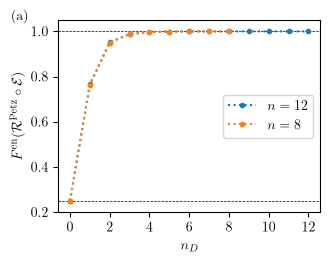

In [13]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
})

width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(
    figsize=(width_in, height_in),
    tight_layout=True
)

ax.axhline(
    y=0.25,
    color='black',
    linestyle='--',
    linewidth=0.5
)

ax.axhline(
    y=1,
    color='black',
    linestyle='--',
    linewidth=0.5
)
ax.plot(range(0, 13), f_petz12_hp, 'o:', label=r'$n=12$',markersize=3)
ax.plot(range(0, 9), f_petz8_hp, 'o:', label=r'$n=8$', markersize=3)

ax.set_ylim(0.2, 1.05)

ax.set_ylabel(r'$F^{\mathrm{en}}(\mathcal{R}^{\mathrm{Petz}}\circ \mathcal{E})$')
ax.set_xlabel(r'$n_D$')

ax.legend()
plt.xticks(range(0,13,2))

plt.text(-0.18, 1, '(a)', transform=plt.gca().transAxes)


fig.savefig(
    'figure/petz_fidelity_hp.pdf',
    bbox_inches='tight'
)

#### Scaled singular-value spectrum

For comparison with unassisted encoding, we again use the $n=8$ unitary `U8`, with $n_A=1$, and vary $n_D$ from zero to eight. The reduced type-II′ HP block encoding has $\alpha=\sqrt{d_D/d_B}$ and rank $r=\min(d_A d_C,d_Dd_B)$ almost surely. Thus

$$
x_{\mathrm{rms}}=\sqrt{\overline{x^2}}
=\frac{1}{\sqrt{r\alpha^2}}
=\frac{1}{\min(d_A,d_D)},
\qquad x_i=\lambda_i/\alpha.
$$

For one logical qubit, $n_A=1$ and $d_A=2$: $x_{\mathrm{rms}}=1/2$ for $n_D\geq1$, and $x_{\mathrm{rms}}=1$ at $n_D=0$.

As in the Haar example, the left panel shows $[x_{\min},x_{\max}]$ and $x_{\mathrm{rms}}$, while the right panel shows $k^*(x)=\pi/[4\arcsin x]-1/2$ at the minimum and RMS values. The RMS estimate is one iteration for $n_D\geq1$; finite spectral width limits how well a single Grover iteration approximates Petz recovery.


In [14]:
# Entanglement-assisted Hayden-Preskill encoding: n=8 and one logical qubit.
N, A = 8, 1
B = N - A
hp_n_D = np.arange(N + 1)
hp_x_min, hp_x_max, hp_x_rms = [], [], []

for D in tqdm(hp_n_D):
    E_d = petz.generate_random_encoding(U8, D=D, A=A, entanglement=True)
    s = np.linalg.svd(E_d, compute_uv=False)
    alpha = np.sqrt(2**D / 2**B)
    # Bound roundoff at x=1 before evaluating arcsin.
    x = np.minimum(s / alpha, 1.0)
    hp_x_min.append(np.min(x))
    hp_x_max.append(np.max(x))
    hp_x_rms.append(np.sqrt(np.mean(x**2)))

hp_x_min = np.array(hp_x_min)
hp_x_max = np.array(hp_x_max)
hp_x_rms = np.array(hp_x_rms)
hp_k_min = np.pi / (4*np.arcsin(hp_x_min)) - 0.5
hp_k_rms = np.pi / (4*np.arcsin(hp_x_rms)) - 0.5


100%|██████████| 9/9 [00:00<00:00, 184.76it/s]


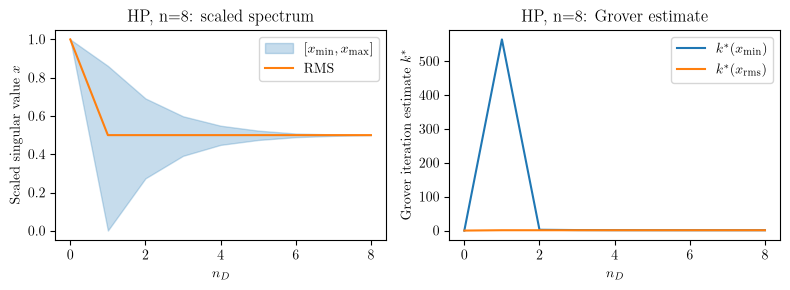

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), tight_layout=True)

axes[0].fill_between(
    hp_n_D, hp_x_min, hp_x_max,
    color='tab:blue', alpha=0.25, label=r'$[x_{\min},x_{\max}]$'
)
axes[0].plot(hp_n_D, hp_x_rms, color='tab:orange', label='RMS')
axes[0].set_xlabel(r'$n_D$')
axes[0].set_ylabel(r'Scaled singular value $x$')
axes[0].set_title('HP, n=8: scaled spectrum')
axes[0].legend()

axes[1].plot(hp_n_D, hp_k_min, label=r'$k^*(x_{\min})$')
axes[1].plot(hp_n_D, hp_k_rms, label=r'$k^*(x_{\mathrm{rms}})$')
axes[1].set_xlabel(r'$n_D$')
axes[1].set_ylabel(r'Grover iteration estimate $k^*$')
axes[1].set_title('HP, n=8: Grover estimate')
axes[1].legend()

fig.savefig('figure/spectrum_hp.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)


#### Approximate Petz recovery

We compare the four angle sequences introduced above using $n=8$, $n_A=1$, $n_D=2$, and the reduced type-II′ HP normalization $\alpha=\sqrt{d_D/d_B}$. The setup cell calls `calculate_fidelity_curve` for each sequence with `entanglement=True`. The following combined plot shows the unconditional fidelities versus $k$ and the ideal HP Petz benchmark. A spectrum concentrated near $x=1/2$ gives the Grover estimate $k^*=1$.


In [16]:
# Shared Hayden-Preskill setup: one logical qubit, n=8, and n_D=2.
N, A, D = 8, 1, 2
B, C = N - A, N - D
K = np.arange(10)  # QSVT iterations; each sequence contains 2*k angles.

# Scaled singular values for the reduced type-II HP block encoding.
E_d = petz.generate_random_encoding(U8, D=D, A=A, entanglement=True)
s = np.linalg.svd(E_d, compute_uv=False)
alpha = np.sqrt(2**D / 2**B)
x = s / alpha
a, b = np.min(x), np.max(x)
f_petz = f_petz8_hp[D]

# 1. Spectrum-weighted sequence: use the full scaled spectrum x.
f_weighted, f_weighted_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_weighted_angles(2*k, lambdas=x),
    A=A, entanglement=True
)

# 2. Tight-interval sequence: optimize on [x_min, x_max] = [a, b].
f_intb, f_intb_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_interval_angles(2*k, a=a, b=b),
    A=A, entanglement=True
)

# 3. Lower-bound sequence: optimize on [x_min, 1] = [a, 1].
f_int, f_int_p = calculate_fidelity_curve(
    U8, D, K, lambda k: qsvt.generate_interval_angles(2*k, a=a, b=1),
    A=A, entanglement=True
)

# 4. Grover sequence: all 2*k angles equal pi.
f_grover, f_grover_p = calculate_fidelity_curve(
    U8, D, K, lambda k: np.pi*np.ones(2*k), A=A, entanglement=True
)
# Arrays ending in _p contain postselected fidelities; the plot uses deterministic ones.


100%|██████████| 10/10 [00:00<00:00, 72.66it/s]


/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/slxu/miniconda3/envs/research/lib/python3.14/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


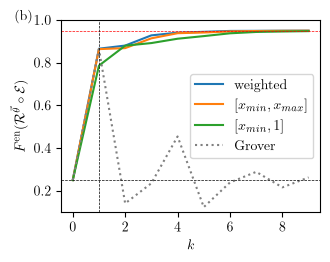

In [17]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 10,
})

width_pt = 246
width_in = width_pt / 72.27
height_in = width_in * 0.8

fig, ax = plt.subplots(
    figsize=(width_in, height_in),
    tight_layout=True
)


plt.plot(K, f_weighted, label='weighted')
plt.plot(K, f_intb, label='$[x_{min},x_{max}]$')
plt.plot(K, f_int, label='$[x_{min},1]$')
plt.plot(K, f_grover,'grey',linestyle=':',label='Grover')
plt.axhline(y=f_petz, color='r', linestyle='--', linewidth=0.5)
plt.axhline(y=0.25, color='black', linestyle='--', linewidth=0.5)
plt.ylim(0.1, 1)
plt.xlabel('$k$')
plt.ylabel(r'$F^{\mathrm{en}}(\mathcal{R}^{\vec \theta}\circ\mathcal{E})$')
plt.legend()
plt.text(-0.18, 1, '(b)', transform=plt.gca().transAxes)
plt.axvline(x=np.pi/4/np.arcsin(1/2)-1/2, color='black', linestyle='--', label='Reference vertical line', linewidth=0.5)
fig.savefig("figure/fidelity_vs_k_hp.pdf")